# GPT Explorations 2 - Small GPT-2

## 1. Objective😎

We are going to train the model with actual dataset.

To see an in-depth explaination of the building blocks of GPT, you can refer to the 5<sup>th</sup> notebook.


## 2. Configuration
Here are the configurations of all GPT-2 models.

In [1]:
GPT_CONFIGS = {
    "Tiny": {
        "emb_dim": 32,
        "n_layers": 2,
        "n_heads": 4
    },
    "Small": {
        "emb_dim": 384,
        "n_layers": 6,
        "n_heads": 6
    },  
    "124M": {
        "emb_dim": 768,
        "n_layers": 12,
        "n_heads": 12
    },
    "355M": {
        "emb_dim": 1024,
        "n_layers": 24,
        "n_heads": 16
    },
    "774M": {
        "emb_dim": 1280,
        "n_layers": 36,
        "n_heads": 20
    },
    "1558M": {
        "emb_dim": 1600,
        "n_layers": 48,
        "n_heads": 25
    }
}

# Select model
model_size = "Small"

GPT_CONFIG = {
    "vocab_size": 50257,
    "context_length": 1024,
    "drop_rate": 0.1,
    "qkv_bias": False,
    **GPT_CONFIGS[model_size]
}

## 3. The Building Blocks of GPT
- ### Layer Normalization

In [2]:
import torch
import torch.nn as nn

In [3]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5 #Avoid division by 0.

        # They are registered to be model parameters, that the optimizer will update them while training
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.ones(emb_dim))

    def forward(self,x):
        # Calculate mean, variance, and then normalized data points.
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, correction=0)
        norm_x = (x-mean)/torch.sqrt(var+self.eps)
        return self.scale * norm_x + self.shift

- ### Feed Forward Neural Network

In [4]:
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4*cfg["emb_dim"]), # Expansion
            nn.GELU(approximate="tanh"), # Activation
            nn.Linear(4*cfg["emb_dim"], cfg["emb_dim"]) # Contraction
        )
    def forward(self,x):
        return self.layers(x)

- ### Residual Connection

This building block is a bit different, and it is integrated in the `GPTModel` class.

- ### Multi Head Attention

In [5]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads # Reduce the projection dim to match the desired output dim
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out) # Linear layer to combine head inputs
        self.dropout = nn.Dropout(dropout) # Floor division
        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length), diagonal = 1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape

        keys = self.W_key(x) # Shape: (b, num_tokens, d_out)
        queries = self.W_query(x)
        values = self.W_value(x)

        # We implicitly split the matrix by adding a 'num_heads' dimension
        # Unroll the last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)

        # Transpose: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        # Compute scaled dot-product attention (self-attention) with a causal mask
        attn_scores = queries @ keys.transpose(2, 3) # Dot product for each head
        # (b, num_heads, num_tokens, num_tokens)

        attn_scores.masked_fill_(self.mask.bool()[:num_tokens, :num_tokens], -torch.inf)
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        # Shape: (b, num_tokens, num_heads, head_dim)
        context_vec = (attn_weights @ values).transpose(1,2)

        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)
        # Combine all heads back into one unified representation.

        return context_vec



## 4. The Transformer Block and the GPT Model

In [6]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in = cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"]
        )
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        # Residual connection for attention block
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)             # Shape (batch_size, num_tokens, emb_size)
        x = self.drop_shortcut(x)
        x = x + shortcut            # Add the original input back

        # Residual connection for feedforward block
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        return x

In [7]:
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        nn.init.normal_(self.tok_emb.weight, mean=0.0, std=0.02)
        nn.init.normal_(self.pos_emb.weight, mean=0.0, std=0.01)
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        # creates a sequential stack of TransformerBlock modules equal to the number of layers specified in cfg.
        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])]
        )
        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False) # No bias
        # Projects the transformer's output into the vocabulary space of the tokenizer to generate logits for each token in the vocabulary.
        self.out_head.weight = self.tok_emb.weight # Weight tying
        # Thus, Input Embedding and Output Head will maintain a same weight

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

## 5. Generating text from output tokens

In [41]:
def generate_text_simple(model, idx, max_new_tokens, context_size):
    eos_id = 50256
    for _ in range(max_new_tokens):
        # Crop current context if it exceeds the supported context size
        idx_cond = idx[:, -context_size:]
        # Select all rows (batches), slice columns (tokens) from end to cound backwards.

        # Get the predictions
        with torch.no_grad(): # The model won't need to update parameters during inference
            logits = model(idx_cond) # shape (batch, num_tokens, vocab_size)

        # Focus only on the last time step
        # Shape contverted to: (batch, vocab_size)
        logits = logits[:, -1, :]
        # Keep all batches; selects only the last position in the sequence; keeps the entire vocabulary

        # Get the idx of the vocab entry with the highest probability value
        # aka greedy selection
        idx_next = torch.argmax(logits, dim=-1, keepdim=True) # shape (batch, 1)

        if idx_next.item() == eos_id:
            break
        # Append sampled index to the running sequence
        idx = torch.cat((idx, idx_next), dim=1) # (batch, n_tokens+1)

    return idx

## 6. Evaluating Generative Text Models

In [9]:
def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={'<|endoftext|>'})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0) # add batch dimension
    return encoded_tensor

def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0) # remove batch dimension
    return tokenizer.decode(flat.tolist())

## 7. Calculating the training and validation set losses
<div class="alert alert-block alert-success">

We are going to use a relatively small dataset for the training process for educational purposes.

To be honest, writing requires quite amount of effort for skills and proficiency. So while I was having Toefl writing classes, I have written a bunch of writing practices. Now I am going to use those as the dataset to train the model.🤣
</div>

In [10]:
import tiktoken, os
tokenizer = tiktoken.get_encoding('gpt2')

file_path = "TinyStories.txt"

if not os.path.exists(file_path):
    print(f"Cannot find the dataset {file_path}")
else:
    with open(file_path, "r") as file:
        text_data = file.read()

In [11]:
total_characters = len(text_data)
total_tokens = len(tokenizer.encode(text_data, allowed_special={'<|endoftext|>'}))

print("Characters:", total_characters)
print("Tokens:", total_tokens)

Characters: 19432979
Tokens: 4724503


### DataLoader

In [12]:
from torch.utils.data import Dataset, DataLoader


class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        # Tokenize the entire text
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})

        # Use a sliding window to chunk the book into overlapping sequences of max_length
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]


def create_dataloader_v1(txt, batch_size=4, max_length=256, 
                         stride=128, shuffle=True, drop_last=True,
                         num_workers=0):

    # Initialize the tokenizer
    tokenizer = tiktoken.get_encoding("gpt2")

    # Create dataset
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)

    # Create dataloader
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )

    return dataloader

In [13]:
train_ratio = 0.80
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]
torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG["context_length"],
    stride=GPT_CONFIG["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)

val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG["context_length"],
    stride=GPT_CONFIG["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)

In [14]:
print("Number of training samples:", len(train_loader.dataset))
print("Number of validation samples:", len(val_loader.dataset))
print("Number of training batches:", len(train_loader))
print("Number of validation batches", len(val_loader))

if len(train_loader) == 0:
    raise ValueError(
        "Validation set has no full batches, please reduce context_length, "
        "reduce batch_size, or increase training data"
    )

if len(val_loader) == 0:
    raise ValueError(
        "Validation set has no full samples, please reduce context_length, "
        "or increase validation data"
    )

# 看一个训练 batch 的形状
input_batch, target_batch = next(iter(train_loader))

print("Input shape:", input_batch.shape)
print("Target shape:", target_batch.shape)

Number of training samples: 3693
Number of validation samples: 920
Number of training batches: 1846
Number of validation batches 460
Input shape: torch.Size([2, 1024])
Target shape: torch.Size([2, 1024])


<div class="alert alert-block alert-success">

Two optional checks that the data was loaded correctly:

</div>

In [15]:
print("Train loader:")
for x, y in train_loader:
    print(x.shape, y.shape)

print("\nValidation loader:")
for x, y in val_loader:
    print(x.shape, y.shape)

print(len(train_loader))
print(len(val_loader))


Train loader:
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 102

In [16]:
train_tokens = 0
for input_batch, target_batch in train_loader:
    train_tokens += input_batch.numel()

val_tokens = 0
for input_batch, target_batch in val_loader:
    val_tokens += input_batch.numel()

print("Training tokens:", train_tokens)
print("Validation tokens:", val_tokens)
print("All tokens:", train_tokens + val_tokens)

Training tokens: 3780608
Validation tokens: 942080
All tokens: 4722688


<div class="alert alert-block alert-success">

Next, we implement a utility function to calculate the cross-entropy loss of a given batch.

In addition, we implement a second utility function to compute the loss for a user-specified number of batches in a data loader.
</div>

In [17]:
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)
    loss = torch.nn.functional.cross_entropy(logits.flatten(0, 1), target_batch.flatten())
    return loss

def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0.
    if len(data_loader) == 0:
        return float("nan")
        # Avoid division by zero
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        # Ensure num_batches (if specified) is less than actual batch number the length of the dataloader.
        num_batches = min(num_batches, len(data_loader))
    
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
            # item() to significantly reduce memory footprint (tensor -> float)
        else:
            break
    return total_loss / num_batches

<div class="alert alert-block alert-info">

If you have a machine with a CUDA-supported GPU, the LLM will train on the GPU without making any changes to the code.
    
Via the device setting, we ensure that the data is loaded onto the same device as the LLM model.
    
</div>

In [18]:
#device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Note:
# Uncommenting the following lines will allow the code to run on Apple Silicon chips, if applicable,
# which is approximately 2x faster than on an Apple CPU (as measured on an M3 MacBook Air).
# However, the resulting loss values may be slightly different.

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available(): # Apple Silicon (M series chip) Metal Performance Shader
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Using {device} device.")

model = GPTModel(GPT_CONFIG)
model.to(device) # no assignment model = model.to(device) necessary for nn.Module classes

Using mps device.


GPTModel(
  (tok_emb): Embedding(50257, 384)
  (pos_emb): Embedding(1024, 384)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=384, out_features=384, bias=False)
        (W_key): Linear(in_features=384, out_features=384, bias=False)
        (W_value): Linear(in_features=384, out_features=384, bias=False)
        (out_proj): Linear(in_features=384, out_features=384, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=384, out_features=1536, bias=True)
          (1): GELU(approximate='tanh')
          (2): Linear(in_features=1536, out_features=384, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query):

## 8. Training loop for the LLM

<div class="alert alert-block alert-info">

The evaluate_model function calculates the loss over the training and
validation set while ensuring the model is in evaluation mode with gradient tracking and
dropout disabled when calculating the loss over the training and validation sets
    
</div>

In [19]:
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss

<div class="alert alert-block alert-info">

The generate_and_print_sample function is a convenience function that we use to track whether the model improves during the training. 

In particular, the generate_and_print_sample function takes a text snippet (start_context) as input,
converts it into token IDs, and feeds it to the LLM to generate a text sample using the
generate_text_simple function we used earlier
    
</div>

In [20]:
def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple(
            model=model, idx=encoded,
            max_new_tokens=50, context_size=context_size
        )
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))  # Compact print format
    model.train()

In [21]:
def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                       eval_freq, eval_iter, start_context, tokenizer, early_stopping):
    if eval_freq < 1:
        raise ValueError("eval_freq must be >= 1")
    if num_epochs < 1 or len(train_loader) == 0:
        raise ValueError("num_epochs and len(train_loader) must be >= 1")

    best_val_loss = float("inf")
    best_epoch = 0
    patience = 20
    counter = 0
    stop_training = False

    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, 0

    for epoch in range(num_epochs):
        model.train()

        for batch_idx, (input_batch, target_batch) in enumerate(train_loader):
            optimizer.zero_grad(set_to_none=True)

            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward()
            optimizer.step()

            tokens_seen += input_batch.numel()
            global_step += 1

            is_final_step = (
                epoch == num_epochs - 1
                and batch_idx == len(train_loader) - 1
            )

            if global_step % eval_freq == 0 or is_final_step:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter
                )

                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)

                print(
                    f"Epoch {epoch + 1}/{num_epochs} | "
                    f"Step {global_step:06d} | "
                    f"Train Loss: {train_loss:.4f} | "
                    f"Validation Loss: {val_loss:.4f}"
                )

                if early_stopping:
                    if val_loss < best_val_loss:
                        best_val_loss = val_loss
                        best_epoch = epoch + 1
                        counter = 0

                        torch.save(
                            {
                                "model_state_dict": model.state_dict(),
                                "optimizer_state_dict": optimizer.state_dict(),
                                "config": dict(GPT_CONFIG),
                                "epoch": best_epoch,
                                "global_step": global_step,
                                "val_loss": best_val_loss,
                            },
                            "best_model.pth"
                        )
                    else:
                        counter += 1

                    if counter >= patience:
                        print(
                            f"Early stopping at epoch {epoch + 1}, "
                            f"step {global_step}"
                        )
                        stop_training = True
                        break

        generate_and_print_sample(
            model, tokenizer, device, start_context
        )

        if stop_training:
            break

    if early_stopping:
        print(f"Best epoch: {best_epoch}")
        print(f"Best validation loss: {best_val_loss:.4f}")

    return train_losses, val_losses, track_tokens_seen, epoch

<div class="alert alert-block alert-success">

Let's see this all in action by training a GPTModel instance for 10 epochs using an AdamW
optimizer and the train_model_simple function we defined earlier.
</div>

Execute the following cell will start training the GPT-2 model based on the selection of the model.

In [ ]:
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0001, weight_decay=0.01)

In [59]:
import time
start_time = time.time()

model.to(device)

for group in optimizer.param_groups:
    group["lr"] = 0.00005

num_epochs = 10
eval_freq = 100
train_losses, val_losses, tokens_seen, final_epoch = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=eval_freq, eval_iter=10,
    start_context='Every effort moves you', tokenizer=tokenizer,early_stopping=False
)


end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

Epoch 1/10 | Step 000100 | Train Loss: 4.1047 | Validation Loss: 4.3268
Epoch 1/10 | Step 000200 | Train Loss: 4.0779 | Validation Loss: 4.3250
Epoch 1/10 | Step 000300 | Train Loss: 4.1173 | Validation Loss: 4.3244
Epoch 1/10 | Step 000400 | Train Loss: 4.0793 | Validation Loss: 4.3242
Epoch 1/10 | Step 000500 | Train Loss: 4.1792 | Validation Loss: 4.3269
Epoch 1/10 | Step 000600 | Train Loss: 4.0566 | Validation Loss: 4.3269
Epoch 1/10 | Step 000700 | Train Loss: 4.1841 | Validation Loss: 4.3229


KeyboardInterrupt: 

<div class="alert alert-block alert-success">

Let's create a simple plot that shows the training and validation set losses side by side
</div>

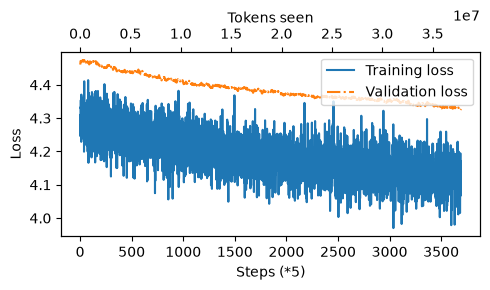

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5,3))

    # Plot training and validation loss against epochs
    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
    ax1.set_xlabel(f"Steps (*{eval_freq})")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True)) # Only show integer labels on x-axis

    # Create a second x-axis for tokens seen
    ax2 = ax1.twiny() # Sharing the same y-axis as ax1
    ax2.plot(tokens_seen, train_losses, alpha=0) # Invisible plot for aligning ticks
    ax2.set_xlabel("Tokens seen")

    fig.tight_layout() # Adjust layout to make room
    plt.show()

epochs_tensor = torch.arange(1, len(train_losses) + 1)
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)


## 9. Decoding strategies to control randomness

<div class="alert alert-block alert-success">

Let's plug the GPTModel instance (model) into the generate_text_simple function,
which uses the LLM to generate one token at a time:
</div>

In [ ]:
tokenizer = tiktoken.get_encoding("gpt2")

model.to("cpu")
model.eval() # Switch to evaluation mode to prevent dropout
token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids("One day, l", tokenizer),
    max_new_tokens=250,
    context_size=GPT_CONFIG["context_length"]
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 One day, l day.



### Generating with Temperature Scaling and Top-k sampling


In [ ]:
def generate(model, idx, max_new_tokens, context_size, temperature=0.0, top_k=None, eos_id=None):

    # For-loop is the same as before: Get logits and only focus on the last time step
    for _ in range (max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]

        # New: Filter logits with top_k sampling
        if top_k is not None:
            # Keep only top_k values
            top_logits, _ = torch.topk(logits, top_k)
            min_val = top_logits[:, -1]
            logits = torch.where(
                logits < min_val,
                torch.tensor(float("-inf")).to(logits.device),
                logits
            )

        # New: Apply temperature scaling
        if temperature > 0.0:
            logits = logits / temperature

            #Apply softmax to get probabilities
            probs = torch.softmax(logits, dim=-1) # (batch_size, context_len)

            # Sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1) # (batch_size, 1)

        # Otherwise same as before: get index of the vocab entry wit hthe highest logits value
        else:
            idx_next = torch.argmax(logits, dim=-1, keepdim=True) # (batch_size, 1)

        if idx_next == eos_id: #Stop generating early if end-of-sequence token is encountered and eos_id is specified
            break

        #Same: append sampled index to the running sequence
        idx =torch.cat((idx, idx_next), dim=-1) # (batch_size, num_tokens+1)
    return idx

<div class="alert alert-block alert-success">

Let's now see this new generate function in action:
</div>

In [ ]:
torch.manual_seed(123)

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer),
    max_new_tokens=15,
    context_size=GPT_CONFIG["context_length"],
    top_k=25,
    temperature=1.4
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you't too boy came. They� Lily felt a little cat saw to eat


<div class="alert alert-block alert-success">

As we can see, the generated text is very different from the one we previously generated
via the generate_simple function earlier which was a memorized passage
from the training set.

</div>

## 10. Save the model

In [ ]:
def save_model(choice, model, optimizer, config):
    if choice.lower().strip() == "y":
        model_name = input("Model Name:").strip()

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "config": dict(config),
            },
            f"{model_name}.pth"
        )

        print(f"Saved: {model_name}.pth")

In [60]:
whether_save = input(f'Save the final model?')
save_model(whether_save, model, optimizer, GPT_CONFIG)

Saved: SmallGPT2_11-5.pth.pth


Resume training in Jupyter Notebook
```Python
checkpoint = torch.load(
    "你的模型名称.pth",
    map_location="cpu",
    weights_only=True
)

model = GPTModel(checkpoint["config"]).to(device)
model.load_state_dict(checkpoint["model_state_dict"])

optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004)
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
```